# Import pandas so we can analyze CSV data.


In [33]:
import pandas as pd

In [34]:
df = pd.read_csv(r"C:\projects\smart-community\ml_service\data\raw\train.csv")


In [35]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [36]:
df.head(20)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [37]:
print("Dataset shape:", df.shape)

Dataset shape: (159571, 8)


In [38]:
print(df.columns.tolist())

['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [39]:
df[["comment_text"]].head()

,comment_text
0,Explanation\nWhy the edits made under my usern...
1,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ..."
4,"You, sir, are my hero. Any chance you remember..."


In [40]:
label_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print(df[label_columns].sum())

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


## Count missing values in each column.

In [41]:
print("Missing values:")
print(df.isnull().sum())


Missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


## Count duplicate comment texts.


In [42]:
print("\nDuplicate comments:", df["comment_text"].duplicated().sum())


Duplicate comments: 0


In [43]:
import matplotlib.pyplot as plt

In [44]:
label_counts = df[label_columns].sum()
print(label_counts)

toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64


In [45]:
# percentage of comments carrying each label
print((df[label_columns].mean() * 100).round(2))

toxic            9.58
severe_toxic     1.00
obscene          5.29
threat           0.30
insult           4.94
identity_hate    0.88
dtype: float64


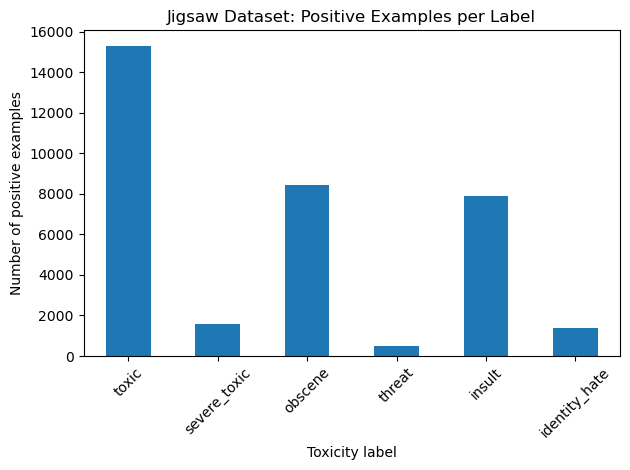

In [46]:
# Plot the number of positive examples for each label.
label_counts.plot(kind="bar")

plt.title("Jigsaw Dataset: Positive Examples per Label")
plt.xlabel("Toxicity label")
plt.ylabel("Number of positive examples")
plt.xticks(rotation=45) #Tilts the label names by 45 degrees so they don’t overlap.
plt.tight_layout() #Adjusts spacing so nothing gets cut off at the edges.
plt.show()

In [47]:
# clean vs toxic overall
df["any_toxic"] = (df[label_columns].sum(axis=1) > 0).astype(int)
print(df["any_toxic"].value_counts())
print((df["any_toxic"].value_counts(normalize=True) * 100).round(1))
#ratio of clean to toxic
counts = df["any_toxic"].value_counts()
print("Clean per 1 toxic:", round(counts[0] / counts[1], 1))

any_toxic
0    143346
1     16225
Name: count, dtype: int64
any_toxic
0    89.8
1    10.2
Name: proportion, dtype: float64
Clean per 1 toxic: 8.8


In [48]:
df = df.drop_duplicates(subset="comment_text").reset_index(drop=True)

#Light Text Cleaning

In [49]:
import re

In [50]:
def clean_text(text):
    text = str(text).lower()                       # 1
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # 2
    text = re.sub(r"\d{1,3}(\.\d{1,3}){3}", " ", text)  # 3
    text = re.sub(r"@\w+", " ", text)              # 4
    text = re.sub(r"(.)\1{3,}", r"\1\1\1", text)   # 5
    text = re.sub(r"\s+", " ", text).strip()       # 6
    return text

In [51]:
tests = [
    "You are an IDIOT!!!!!! Visit http://spam.com",
    "f*ck off\n\n  you   id!ot",
    "@john that was sooooooo stuuuuupid 192.168.0.1",
]
for t in tests:
    print(repr(clean_text(t)))

'you are an idiot!!! visit'
'f*ck off you id!ot'
'that was sooo stuuupid'


In [52]:
df["clean_text"] = df["comment_text"].apply(clean_text)

In [53]:
df[["comment_text", "clean_text"]].sample(5, random_state=1)

,comment_text,clean_text
24915,"YOU ARE A FAT, GEEKY PRICK WHO HAS NOTHING TO ...","you are a fat, geeky prick who has nothing to ..."
75819,Agent X2: Basically thanks - with a 'little' m...,agent x2: basically thanks - with a 'little' m...
53891,Why are my posts being deleted? \n\nI have tri...,why are my posts being deleted? i have tried t...
154159,"""\n\n Controlled Demolitions and Common Sense ...",""" controlled demolitions and common sense - re..."
13040,I do not understand your reply. //Blaxthos ( ...,i do not understand your reply. //blaxthos ( t...


In [54]:
print("Empty after cleaning:", (df["clean_text"] == "").sum())
df = df[df["clean_text"] != ""]

print("Duplicates:", df["clean_text"].duplicated().sum())
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
print(df.shape)

Empty after cleaning: 9
Duplicates: 373
(159189, 10)


In [55]:
print(df[label_columns].sum())

toxic            15226
severe_toxic      1590
obscene           8410
threat             474
insult            7844
identity_hate     1396
dtype: int64


In [56]:
df["any_toxic"] = (df[label_columns].sum(axis=1) > 0).astype(int)
print(df["any_toxic"].value_counts())

any_toxic
0    143035
1     16154
Name: count, dtype: int64


In [57]:
from sklearn.model_selection import train_test_split

# 70% train, 30% held back
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["any_toxic"]
)

# split the 30% into 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["any_toxic"]
)

print(len(train_df), len(val_df), len(test_df))

111432 23878 23879


In [58]:
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(part), "toxic share:", round(part["any_toxic"].mean() * 100, 2), "%")

print(train_df[label_columns].sum())
print(val_df[label_columns].sum())
print(test_df[label_columns].sum())

train 111432 toxic share: 10.15 %
val 23878 toxic share: 10.15 %
test 23879 toxic share: 10.15 %
toxic            10675
severe_toxic      1101
obscene           5839
threat             332
insult            5448
identity_hate      977
dtype: int64
toxic            2273
severe_toxic      262
obscene          1300
threat             79
insult           1229
identity_hate     214
dtype: int64
toxic            2278
severe_toxic      227
obscene          1271
threat             63
insult           1167
identity_hate     205
dtype: int64


In [59]:
import os
os.makedirs(r"C:\projects\smart-community\ml_service\data\processed", exist_ok=True)

train_df.to_csv(r"C:\projects\smart-community\ml_service\data\processed\train.csv", index=False)
val_df.to_csv(r"C:\projects\smart-community\ml_service\data\processed\val.csv", index=False)
test_df.to_csv(r"C:\projects\smart-community\ml_service\data\processed\test.csv", index=False)

In [60]:
import numpy as np
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

In [61]:
word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=100000)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=100000)

X_train = hstack([word_vec.fit_transform(train_df["clean_text"]),
                  char_vec.fit_transform(train_df["clean_text"])]).tocsr()

X_val = hstack([word_vec.transform(val_df["clean_text"]),
                char_vec.transform(val_df["clean_text"])]).tocsr()

print(X_train.shape, X_val.shape)

(111432, 200000) (23878, 200000)


In [62]:
models = {}
val_probs = {}

for label in label_columns:
    clf = LogisticRegression(C=4, class_weight="balanced", max_iter=1000, solver="liblinear")
    clf.fit(X_train, train_df[label])
    models[label] = clf
    val_probs[label] = clf.predict_proba(X_val)[:, 1]
    print("trained:", label)

trained: toxic
trained: severe_toxic
trained: obscene
trained: threat
trained: insult
trained: identity_hate


In [63]:
rows = []
for label in label_columns:
    y_true = val_df[label]
    y_prob = val_probs[label]
    y_pred = (y_prob >= 0.5).astype(int)
    rows.append({
        "label": label,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
    })

import pandas as pd
results = pd.DataFrame(rows).round(3)
results

,label,precision,recall,f1,roc_auc
0,toxic,0.760,0.848,0.801,0.981
1,severe_toxic,0.376,0.679,0.484,0.987
2,obscene,0.800,0.842,0.820,0.990
3,threat,0.500,0.658,0.568,0.991
4,insult,0.682,0.801,0.737,0.982
5,identity_hate,0.397,0.659,0.496,0.987


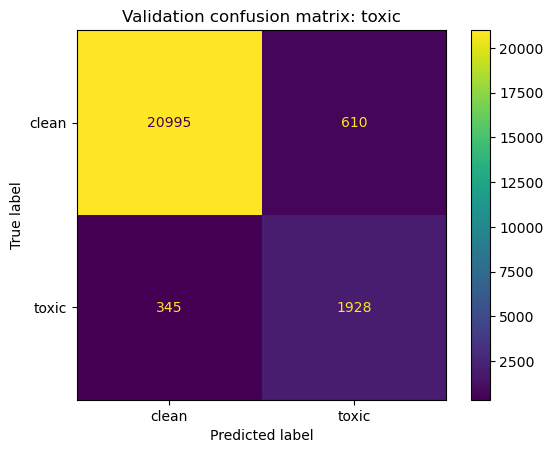

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = (val_probs["toxic"] >= 0.5).astype(int)
cm = confusion_matrix(val_df["toxic"], y_pred)
ConfusionMatrixDisplay(cm, display_labels=["clean", "toxic"]).plot()
plt.title("Validation confusion matrix: toxic")
plt.show()

In [65]:
import joblib
os.makedirs(r"C:\projects\smart-community\ml_service\models", exist_ok=True)
joblib.dump((word_vec, char_vec, models), r"C:\projects\smart-community\ml_service\models\baseline.joblib")

['C:\\projects\\smart-community\\ml_service\\models\\baseline.joblib']